# ETH DCA Backtest (Backtrader, Hourly Check)

策略逻辑：
- 数据：`/Users/dennis/projects/TradingTutorial/data/eth_usdt_1m_1y.csv`
- 使用 1m K 线
- 每小时检查一次（每个小时最后一分钟）
- 若当前价 <= 前一天收盘价 * 0.99，则买入 100 USDT 的 ETH
- 统计输出：累计投入、最终市值、PnL、收益率、夏普率、最大回撤


In [1]:
import backtrader as bt
import pandas as pd
import numpy as np

DATA_PATH = '/Users/dennis/projects/TradingTutorial/data/eth_usdt_1m_1y.csv'
BUY_USDT = 100.0
DROP_PCT = 0.01
INITIAL_CASH = 1_000_000.0  # 给足现金池，策略收益单独按投入资金计算


In [2]:
df = pd.read_csv(DATA_PATH)
df['datetime'] = pd.to_datetime(df['datetime'], utc=True).dt.tz_convert(None)
df = df.sort_values('datetime').set_index('datetime')
df = df[['open', 'high', 'low', 'close', 'volume']].dropna()

df.head(), df.tail(), df.shape

(                        open     high      low    close     volume
 datetime                                                          
 2025-04-03 12:24:00  1794.53  1795.00  1793.67  1793.88   153.1051
 2025-04-03 12:25:00  1793.89  1793.89  1791.09  1791.90   540.9679
 2025-04-03 12:26:00  1791.89  1793.16  1790.46  1790.84   367.3421
 2025-04-03 12:27:00  1790.83  1791.32  1786.49  1787.72  1082.1948
 2025-04-03 12:28:00  1787.71  1788.80  1787.04  1787.13   340.8351,
                         open     high      low    close   volume
 datetime                                                        
 2026-04-03 12:21:00  2061.54  2061.55  2060.92  2061.06  18.2334
 2026-04-03 12:22:00  2061.07  2061.69  2060.06  2060.06  72.4738
 2026-04-03 12:23:00  2060.07  2060.58  2059.79  2059.95  60.9519
 2026-04-03 12:24:00  2059.94  2060.12  2059.45  2060.11  14.9177
 2026-04-03 12:25:00  2060.12  2062.30  2060.12  2062.29  28.9824,
 (523510, 5))

In [3]:
class HourlyDropDCA(bt.Strategy):
    params = dict(
        buy_usdt=100.0,
        drop_pct=0.01,
    )

    def __init__(self):
        self.close = self.datas[0].close

        self.current_day = None
        self.day_close = None
        self.prev_day_close = None
        self.last_close = None

        self.invested = 0.0
        self.buy_count = 0
        self.daily_nav = []
        self.trade_records = []

    def _record_daily_nav(self):
        if self.current_day is None or self.last_close is None:
            return
        if self.invested <= 0:
            return
        pos_value = self.position.size * self.last_close
        nav = pos_value / self.invested
        self.daily_nav.append((self.current_day, nav))

    def next(self):
        dt = self.datas[0].datetime.datetime(0)
        px = float(self.close[0])

        if self.current_day is None:
            self.current_day = dt.date()
            self.day_close = px

        # Day rollover: finalize previous day NAV, then update previous-day close
        if dt.date() != self.current_day:
            self._record_daily_nav()
            self.prev_day_close = self.day_close
            self.current_day = dt.date()
            self.day_close = px
        else:
            self.day_close = px

        # 每小时最后一分钟检查一次
        if dt.minute == 59 and self.prev_day_close is not None:
            trigger_price = self.prev_day_close * (1.0 - self.p.drop_pct)
            if px <= trigger_price:
                size = self.p.buy_usdt / px
                self.buy(size=size)
                self.invested += self.p.buy_usdt
                self.buy_count += 1
                self.trade_records.append((dt, px, self.prev_day_close, size, self.invested))

        self.last_close = px

    def stop(self):
        # Record last day NAV
        self._record_daily_nav()


In [4]:
cerebro = bt.Cerebro(stdstats=False)

data_feed = bt.feeds.PandasData(dataname=df)
cerebro.adddata(data_feed)
cerebro.addstrategy(HourlyDropDCA, buy_usdt=BUY_USDT, drop_pct=DROP_PCT)

cerebro.broker.setcash(INITIAL_CASH)
cerebro.broker.setcommission(commission=0.0)
cerebro.broker.set_coc(True)  # 当根收盘成交，方便按小时收盘价定投

results = cerebro.run()
strat = results[0]

In [5]:
invested = strat.invested
final_price = strat.last_close if strat.last_close is not None else 0.0
final_value = strat.position.size * final_price
pnl = final_value - invested
total_return = (final_value / invested - 1.0) if invested > 0 else np.nan

daily_nav = np.array([x[1] for x in strat.daily_nav], dtype=float)
daily_ret = daily_nav[1:] / daily_nav[:-1] - 1.0 if len(daily_nav) > 1 else np.array([])

if len(daily_ret) > 1 and np.std(daily_ret, ddof=1) != 0:
    sharpe = (np.mean(daily_ret) / np.std(daily_ret, ddof=1)) * np.sqrt(365)
else:
    sharpe = np.nan

if len(daily_nav) > 0:
    running_max = np.maximum.accumulate(daily_nav)
    drawdown = daily_nav / running_max - 1.0
    max_dd = np.min(drawdown)
else:
    max_dd = np.nan

print(f'Buy Count:                {strat.buy_count}')
print(f'Total Invested:           {invested:,.2f} USDT')
print(f'Final Position Value:     {final_value:,.2f} USDT')
print(f'Final PnL:                {pnl:,.2f} USDT')
print(f'Total Return:             {total_return * 100:.2f}%')
print(f'Sharpe Ratio (annualized): {sharpe:.4f}')
print(f'Max Drawdown:             {max_dd * 100:.2f}%')
print(f'Daily NAV Points:         {len(daily_nav)}')

Buy Count:                2167
Total Invested:           216,700.00 USDT
Final Position Value:     168,141.96 USDT
Final PnL:                -48,558.04 USDT
Total Return:             -22.41%
Sharpe Ratio (annualized): 0.0239
Max Drawdown:             -68.80%
Daily NAV Points:         365


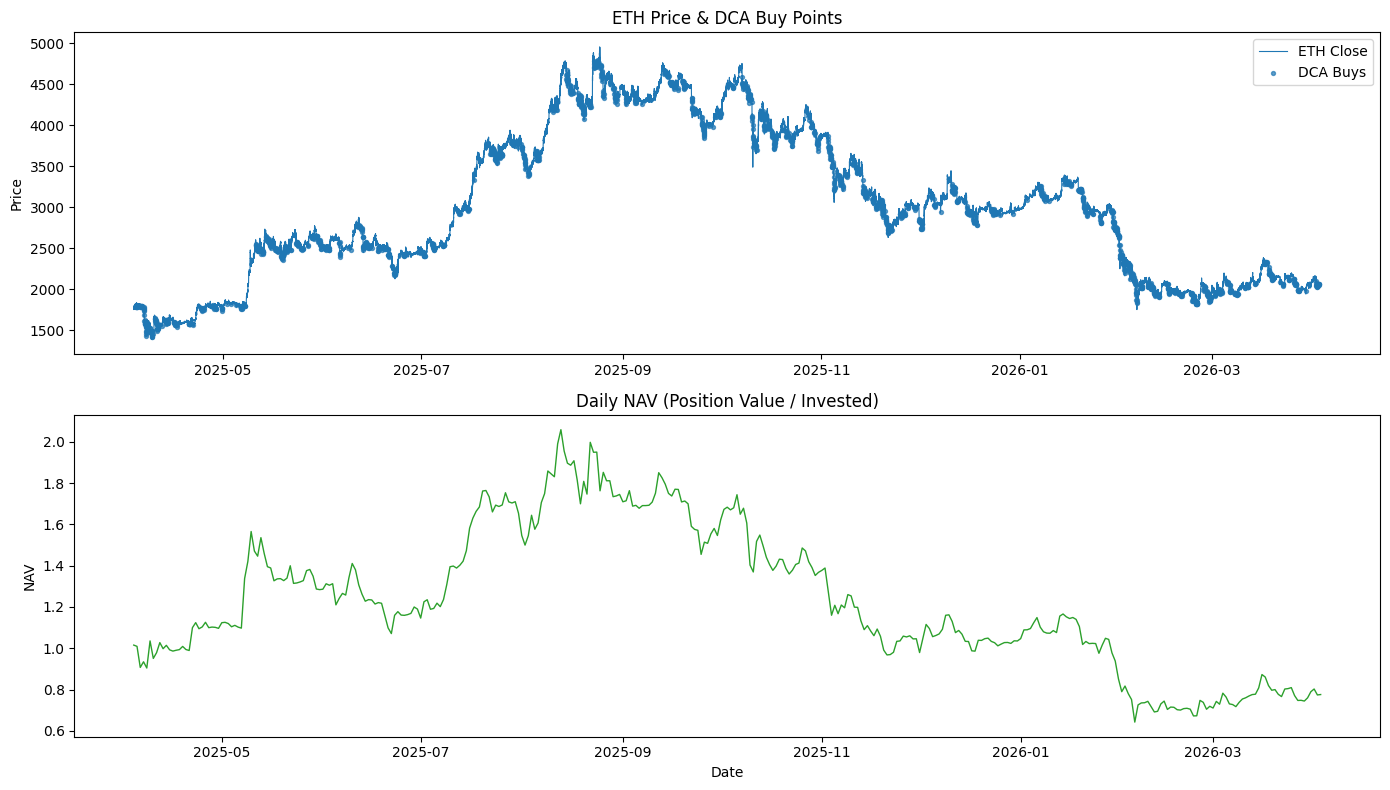

In [6]:
# Optional: visualize
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

axes[0].plot(df.index, df['close'], linewidth=0.8, label='ETH Close')
if strat.trade_records:
    buy_ts = [x[0] for x in strat.trade_records]
    buy_px = [x[1] for x in strat.trade_records]
    axes[0].scatter(buy_ts, buy_px, s=8, alpha=0.7, label='DCA Buys')
axes[0].set_title('ETH Price & DCA Buy Points')
axes[0].set_ylabel('Price')
axes[0].legend()

if len(daily_nav) > 0:
    nav_dates = [x[0] for x in strat.daily_nav]
    axes[1].plot(nav_dates, daily_nav, color='tab:green', linewidth=1.0)
axes[1].set_title('Daily NAV (Position Value / Invested)')
axes[1].set_ylabel('NAV')
axes[1].set_xlabel('Date')

plt.tight_layout()
plt.show()